# 7주차 · 텍스트 데이터의 시각화 — 완성본

**인공지능과 데이터 활용** · 실제 **온라인 댓글 300건**(네이버 영화 한 줄 평)과 **뉴스 기사 제목 350건**(연합뉴스)을
단어로 나눠 세고 **빈도표·막대그래프·워드클라우드**로 시각화한 뒤, 같은 원문으로 받은 **AI 요약·키워드**를 원문 근거로 검증합니다.

| 워크북 | 셀 | 실습본 TODO |
|---|---|---|
| 워크북 0 · 실습 준비 — Colab 열기와 데이터 연결 | 셀 0-1 ~ 0-9 (9개) | 0곳 |
| 워크북 1 · 온라인 댓글 워드클라우드 | 셀 1-1 ~ 1-9 (9개) | 5곳 |
| 워크북 2 · 뉴스 기사 제목 워드클라우드 | 셀 2-1 ~ 2-5 (5개) | 2곳 |
| 워크북 3 · AI 요약·키워드와 비교·검증 | 셀 3-1 ~ 3-9 (9개) | 2곳 |

**따라 하는 방법:** 노션의 워크북 페이지를 위에서부터 읽으며, 이 노트북의 **같은 번호 셀(▶ 셀 0-1, 0-2 …)** 을 `Shift+Enter`로 하나씩 실행합니다.
셀마다 **실행 후 확인**을 보고 내 결과와 비교합니다. 실습본은 `TODO`의 `...`을 채운 뒤 실행합니다. 한 번에 실행하려면 `런타임 → 모두 실행`(약 1~2분).

> 데이터: 네이버 영화 140자평(NSMC, CC0) 300건 · 연합뉴스 기사 제목(KLUE-YNAT, CC BY-SA 4.0) 350건.
> 수업 화면용으로 욕설·성적·혐오 표현은 걸러 냈습니다. 그래도 불편한 문장이 보이면 강의자에게 알려 주세요.


---
# 워크북 0 · 실습 준비 — Colab 열기와 데이터 연결
**목표** Colab 노트북을 열어 내 Drive에 저장하고, 도구를 설치한 뒤, **GitHub · Google Drive · 내 컴퓨터(업로드)** 중 한 곳에 있는 실습 데이터를 노트북에 연결한다. 파일 지문(MD5)으로 수업 원본과 같은 파일인지 확인한다.

## 0단계. Colab 노트북 열고 내 Drive에 저장하기
**Colab**은 브라우저에서 파이썬을 실행하는 Google의 무료 서비스입니다. 노트북(`.ipynb`)은 **설명 칸(텍스트 셀)** 과 **코드 칸(코드 셀)** 이 번갈아 있는 문서입니다.

1. 노션의 **실습본 Colab 열기** 링크를 누릅니다(GitHub에 있는 원본이 열림).
2. 메뉴 **파일 → Drive에 사본 저장** → 내 Drive `Colab Notebooks` 폴더에 내 사본이 생깁니다. **이제부터 사본에서 작업**합니다(원본에서 고친 내용은 저장되지 않음).
3. 코드 셀을 클릭하고 **`Shift + Enter`** → 실행되고 다음 셀로 이동합니다. 셀 왼쪽에 `[1]`처럼 실행 순서 번호가 붙습니다.
4. 왼쪽 **📁 파일** 창: 노트북이 만든 파일(`figures/`, `results/`)과 연결한 Drive가 보입니다.
5. 오래 쉬면 **런타임 연결이 끊기고 변수가 사라집니다** → `런타임 → 이전 셀 실행` 또는 위에서부터 다시 실행합니다.

| 용어 | 뜻 |
|---|---|
| 런타임 | 내 코드를 실제로 실행하는 Google의 임시 컴퓨터. 끊기면 설치·변수·파일이 사라짐 |
| 셀 실행 순서 | 위에서 아래로. 아래 셀은 위 셀이 만든 변수(`comments`, `kiwi` 등)를 씀 |
| 실습본 / 완성본 | 실습본은 `TODO` 칸의 `...`을 직접 채움. 막히면 완성본의 같은 번호 셀과 비교 |

## 1단계. 분석 도구 설치하고 가져오기
Colab에 기본으로 없는 도구 3개를 설치합니다. 처음 한 번(런타임이 새로 시작될 때마다) 실행합니다.

| 도구 | 하는 일 |
|---|---|
| `wordcloud` | 단어 빈도를 글자 크기로 그리는 워드클라우드 |
| `kiwipiepy` (Kiwi) | 한국어 **형태소 분석기** — 문장을 명사·조사·어미 등으로 나눔 |
| `koreanize-matplotlib` | 그래프의 한글이 □□□로 깨지지 않게 나눔고딕 글꼴을 설정 |

**▶ 셀 0-1. 도구 설치** — 실행 후 확인: 오류 없이 끝나면 됩니다(출력이 없거나 경고 몇 줄). 빨간 `ERROR`가 나오면 다시 실행

In [1]:
!pip -q install koreanize-matplotlib wordcloud kiwipiepy   # 한글 그래프·워드클라우드·형태소 분석기 (약 30초)

**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `!pip install 이름` | `!`로 시작하면 파이썬이 아니라 컴퓨터 명령. pip = 파이썬 도구 설치 프로그램 |
| `-q` | 설치 과정 메시지를 짧게(quiet) |

**▶ 셀 0-2. 도구 가져오기와 준비** — 실행 후 확인: `글꼴: NanumGothic.ttf | 형태소 분석기 준비 완료`. `ModuleNotFoundError`면 셀 0-1을 먼저 실행

In [2]:
import os, re, glob, io
from collections import Counter                 # 개수 세기 도구
import numpy as np
import pandas as pd                             # 표(DataFrame) 다루기
import matplotlib.pyplot as plt                 # 그래프
import warnings; warnings.filterwarnings("ignore")
import koreanize_matplotlib                     # import만 하면 그래프 한글이 깨지지 않음
from wordcloud import WordCloud
from kiwipiepy import Kiwi

plt.rcParams["axes.unicode_minus"] = False
# 워드클라우드는 matplotlib 글꼴 설정을 쓰지 않으므로 한글 글꼴 파일 경로를 직접 알려 준다
FONT = sorted(glob.glob(os.path.join(os.path.dirname(koreanize_matplotlib.__file__), "fonts", "NanumGothic*.ttf")))[0]
os.makedirs("figures", exist_ok=True)           # 그림 저장 폴더
os.makedirs("results", exist_ok=True)           # 결과 CSV 저장 폴더
kiwi = Kiwi()                                   # 한국어 형태소 분석기 (만들 때 몇 초 걸림)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 250)                  # 표가 줄바꿈되지 않게
print("글꼴:", os.path.basename(FONT), "| 형태소 분석기 준비 완료")

글꼴: NanumGothic.ttf | 형태소 분석기 준비 완료


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `import pandas as pd` | 도구(모듈)를 가져와 `pd`라는 짧은 이름으로 부름 |
| `from collections import Counter` | 모듈 안의 도구 하나만 꺼내 옴 |
| `os.makedirs("figures", exist_ok=True)` | 폴더 만들기. 이미 있으면 그냥 넘어감 |
| `FONT = ...` | 워드클라우드에 쓸 한글 글꼴 파일(.ttf)의 위치 |
| `kiwi = Kiwi()` | 형태소 분석기를 한 번 만들어 두고 아래에서 계속 사용 |

## 2단계. 실습 데이터는 어디에 있나 — 세 곳 중 하나에서 읽기
실습 데이터 파일은 **똑같은 파일이 세 곳**에 있습니다. 노트북은 그중 한 곳에서 읽으면 됩니다.

| 위치 | 주소 / 경로 | 언제 쓰나 | `DATA_SOURCE` |
|---|---|---|---|
| **GitHub** (수업 저장소) | `https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week07/data/` | 평소 — 아무 준비 없이 바로 읽힘 | `"github"` |
| **Google Drive** (강의7주 `02_데이터` 폴더) | `/content/drive/MyDrive/02_데이터/` (바로가기를 추가한 위치) | 수업 중 GitHub 접속이 안 될 때 | `"drive"` |
| **내 컴퓨터** | 내려받은 CSV 파일을 Colab에 업로드 → `data/` 폴더 | 인터넷·Drive 연결이 모두 어려울 때 | `"upload"` |

기본값 `"auto"`는 **GitHub를 먼저 시도하고, 안 되면 Drive**에서 찾습니다. 대부분은 아무것도 바꾸지 않고 실행하면 됩니다.

**필요한 파일 3개**

| 파일 | 내용 |
|---|---|
| `week07_MANIFEST.csv` | 파일 목록표: 파일 이름·크기·**MD5(파일 지문)**·행 수. 노트북이 이 표로 파일이 맞는지 확인 |
| `week07_comments_300.csv` | 워크북 1: 영화 한 줄 평 300건 (NSMC, CC0) |
| `week07_news_350.csv` | 워크북 2: 연합뉴스 기사 제목 350건 (KLUE-YNAT, CC BY-SA 4.0) |

**Google Drive 데이터를 쓰려면 (처음 한 번)**
1. 강의자가 공유한 **`02_데이터`** 폴더를 엽니다 → 폴더 이름 오른쪽 클릭 → **정리 → 바로가기 추가 → 내 드라이브** 선택.
   (공유 폴더는 그대로는 Colab에서 보이지 않습니다. **내 드라이브에 바로가기**가 있어야 `/content/drive/MyDrive/02_데이터/`로 열립니다.)
2. 노트북 셀 0-3에서 `DATA_SOURCE = "drive"`로 바꾸고 셀 0-3부터 다시 실행합니다.
3. 셀 0-5가 **Drive 연결 창**을 띄웁니다 → 내 Google 계정 선택 → **허용**. 연결되면 왼쪽 📁 창에 `drive/MyDrive`가 보입니다.
4. 바로가기를 다른 폴더 안에 만들었어도 셀 0-5가 내 드라이브에서 `week07_MANIFEST.csv`를 찾아 그 폴더를 씁니다.

**내 컴퓨터 파일을 쓰려면:** Drive `02_데이터`의 `week07_data.zip`(또는 GitHub `data/` 폴더의 파일)을 내려받아 압축을 풀고 → `DATA_SOURCE = "upload"` → 셀 0-6에서 파일 3개 선택.

**▶ 셀 0-3. 데이터 위치 정하기** — 실행 후 확인: `선택: auto`. Drive나 업로드를 쓰려면 첫 줄만 바꾸고 이 셀부터 다시 실행

In [3]:
DATA_SOURCE = "auto"      # "auto"(GitHub → 안 되면 Drive) | "github" | "drive" | "upload"
GITHUB_URL = "https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week07/data/"
DRIVE_FOLDER = "/content/drive/MyDrive/02_데이터/"     # 02_데이터 바로가기를 추가한 위치
MANIFEST = "week07_MANIFEST.csv"                      # 파일 목록표 (이름·크기·MD5)
print("선택:", DATA_SOURCE)

선택: auto


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `DATA_SOURCE = "auto"` | 변수에 문자열을 저장. 아래 셀들이 이 값을 보고 어디서 읽을지 정함 |
| `GITHUB_URL` | GitHub 원본 파일 주소의 앞부분. 뒤에 파일 이름을 붙이면 파일 주소가 됨 |
| `DRIVE_FOLDER` | Drive를 연결하면 내 드라이브는 `/content/drive/MyDrive/` 아래에 보임 |

**▶ 셀 0-4. GitHub 연결 확인 (auto일 때 자동 선택)** — 실행 후 확인: `데이터 위치: github`. GitHub가 안 되면 `GitHub 접속 실패 …` 뒤에 `drive`로 바뀜

In [4]:
import urllib.request

def github_ok():
    """GitHub에서 파일 목록표를 열어 보고 되면 True"""
    try:
        urllib.request.urlopen(GITHUB_URL + MANIFEST, timeout=15)
        return True
    except Exception as e:
        print("GitHub 접속 실패:", type(e).__name__)
        return False

if DATA_SOURCE == "auto":
    DATA_SOURCE = "github" if github_ok() else "drive"
print("데이터 위치:", DATA_SOURCE)

데이터 위치: github


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `def github_ok():` | 함수 정의. 몸통은 4칸 들여쓰기 |
| `try: … except Exception as e:` | 실행해 보고 오류가 나면 멈추지 않고 except 부분을 실행 |
| `urllib.request.urlopen(주소)` | 인터넷 주소의 파일을 엶 |
| `A if 조건 else B` | 조건이 참이면 A, 아니면 B |

**▶ 셀 0-5. Google Drive 연결 (drive일 때만)** — 실행 후 확인: GitHub를 쓰면 `Drive 연결은 건너뜀`. Drive를 쓰면 폴더 경로와 파일 목록(`week07_MANIFEST.csv` 등)이 보여야 함

In [5]:
if DATA_SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")                         # 처음 한 번: 계정 선택 → 허용
    if not os.path.exists(DRIVE_FOLDER + MANIFEST):       # 바로가기를 다른 곳에 만든 경우 → 찾기
        hits = [p for d in range(0, 6)
                for p in glob.glob("/content/drive/MyDrive/" + "*/" * d + MANIFEST)]
        if not hits:
            raise FileNotFoundError("내 드라이브에서 week07_MANIFEST.csv를 찾지 못했습니다. "
                                    "공유받은 02_데이터 폴더를 '바로가기 추가 → 내 드라이브' 했는지 확인하세요.")
        DRIVE_FOLDER = os.path.dirname(hits[0]) + "/"
    print("Drive 폴더:", DRIVE_FOLDER)
    print(sorted(os.listdir(DRIVE_FOLDER)))
else:
    print("Drive 연결은 건너뜀 (DATA_SOURCE =", DATA_SOURCE + ")")

Drive 연결은 건너뜀 (DATA_SOURCE = github)


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `drive.mount("/content/drive")` | 내 Google Drive를 Colab의 `/content/drive` 폴더에 붙임(마운트) |
| `os.path.exists(경로)` | 파일이 있으면 True |
| `glob.glob("…/*/…/파일")` | `*` 자리에 아무 폴더 이름이 와도 되는 경로를 모두 찾음 (여기서는 0~5단계 깊이) |
| `raise FileNotFoundError(…)` | 더 진행할 수 없으니 알아보기 쉬운 메시지와 함께 멈춤 |
| `os.listdir(폴더)` | 폴더 안 파일 이름 목록 |

**직접 바꿔 보기:** 왼쪽 📁 창에서 `drive/MyDrive/02_데이터` 폴더를 오른쪽 클릭 → **경로 복사** → `DRIVE_FOLDER`에 붙여 넣으면 직접 지정할 수 있습니다(끝에 `/`를 붙임).

**▶ 셀 0-6. 내 컴퓨터 파일 업로드 (upload일 때만)** — 실행 후 확인: 평소에는 `업로드는 건너뜀`. 업로드를 쓰면 세 파일 이름이 출력되어야 함

In [6]:
if DATA_SOURCE == "upload":
    from google.colab import files
    os.makedirs("data", exist_ok=True)
    print("week07_MANIFEST.csv, week07_comments_300.csv, week07_news_350.csv 세 파일을 선택하세요.")
    for name, content in files.upload().items():          # 파일 선택 창이 열림
        open("data/" + name, "wb").write(content)
    print(sorted(os.listdir("data")))
else:
    print("업로드는 건너뜀 (DATA_SOURCE =", DATA_SOURCE + ")")

업로드는 건너뜀 (DATA_SOURCE = github)


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `files.upload()` | 파일 선택 창을 열고, 고른 파일을 {이름: 내용} 사전으로 돌려줌 |
| `open(경로, "wb").write(내용)` | 내용을 그대로(바이트) 파일로 저장. w=쓰기, b=바이너리 |

**▶ 셀 0-7. 어디서든 같은 방법으로 읽기 — 파일 목록표 열기** — 실행 후 확인: 4행 표: 댓글 CSV 300행, 뉴스 CSV 350행, 원자료 미러 2개

In [7]:
def read_bytes(name):
    """선택한 위치에서 파일 내용을 그대로(bytes) 읽어 온다"""
    if DATA_SOURCE == "github":
        return urllib.request.urlopen(GITHUB_URL + name, timeout=120).read()
    if DATA_SOURCE == "drive":
        return open(DRIVE_FOLDER + name, "rb").read()
    if DATA_SOURCE == "upload":
        return open("data/" + name, "rb").read()
    return open(os.path.join(DATA_SOURCE, name), "rb").read()   # 폴더 경로를 직접 적은 경우

manifest = pd.read_csv(io.BytesIO(read_bytes(MANIFEST)), encoding="utf-8-sig")
manifest[["file", "bytes", "rows", "note"]]

,file,bytes,rows,note
0,week07_comments_300.csv,32278,300,워크북 1 입력: 네이버 영화 140자평(NSMC) 긍정 150·부정 150
1,week07_news_350.csv,71235,350,워크북 2 입력: 연합뉴스 제목(KLUE-YNAT) 7개 분야 × 50
2,nsmc_ratings.txt.gz,8282350,200000,"댓글 원자료 미러, 압축 해제 MD5=f1f2772629b775ac39a6344e95a2c9a8"
3,ynat_titles_all.csv.gz,2353363,45678,"뉴스 제목 전체본(guid·category·title·date·url), 확장 과제용"


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `def read_bytes(name):` | 어디에 있든 `read_bytes("파일이름")` 한 줄로 읽게 해 주는 함수. 아래 워크북은 이 함수만 씀 |
| `io.BytesIO(내용)` | 메모리에 있는 내용을 파일처럼 다루게 해 줌 → `read_csv`가 읽을 수 있음 |
| `encoding="utf-8-sig"` | 한글 CSV 인코딩. 엑셀에서 연 CSV도 한글이 깨지지 않게 저장한 형식 |
| `manifest[["file", …]]` | 표에서 여러 열만 골라 보기 (대괄호 두 겹) |

**▶ 셀 0-8. 파일 지문(MD5)으로 원본과 같은지 확인** — 실행 후 확인: 두 줄 모두 `정상(MD5 일치)`. GitHub·Drive·업로드 어디서 읽어도 같아야 하며, 그래야 아래 기대값이 똑같이 나옴

In [8]:
import hashlib

def check_file(name):
    """파일을 읽어 MD5를 계산하고 목록표의 값과 비교한다. 같으면 수업 원본과 똑같은 파일"""
    data = read_bytes(name)
    expected = manifest.set_index("file").loc[name, "md5"]
    ok = hashlib.md5(data).hexdigest() == expected
    print(f"{name:26s} {len(data):>7,} bytes → {'정상(MD5 일치)' if ok else '⚠ 다른 파일! 강의자에게 알리세요'}")
    return data

for name in ["week07_comments_300.csv", "week07_news_350.csv"]:
    check_file(name)

week07_comments_300.csv     32,278 bytes → 정상(MD5 일치)


week07_news_350.csv         71,235 bytes → 정상(MD5 일치)


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `hashlib.md5(data).hexdigest()` | 파일 내용으로 32자리 지문을 계산. 한 글자만 달라도 완전히 다른 값 |
| `manifest.set_index("file").loc[name, "md5"]` | 목록표에서 그 파일 행의 md5 값 찾기 |
| `f"{name:26s} {len(data):>7,}"` | f-문자열: 26칸 맞춤, 오른쪽 정렬 7칸에 천 단위 쉼표 |

## 3단계. 그림 그리는 함수 미리 만들기
워크북 1·2에서 막대그래프와 워드클라우드를 여러 번 그립니다. 같은 코드를 반복하지 않도록 **함수**로 만들어 둡니다.
**빈도(Counter)** 만 넣으면 그림을 그리고 `figures/` 폴더에 PNG로 저장합니다.

- **막대그래프**: 상위 단어의 **정확한 개수와 순위**를 비교할 때
- **워드클라우드**: 글자 크기 = 빈도. **한눈에 보는 인상**. 색·위치는 의미 없음

**▶ 셀 0-9. 막대그래프·워드클라우드 함수** — 실행 후 확인: 사과 5·배 3·포도 2 막대그래프가 한글로 보이면 준비 끝. □□□로 보이면 셀 0-2를 다시 실행

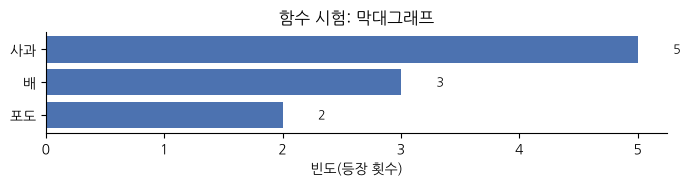

In [9]:
def bar_top(counter, title, fname, n=20, color="#4C72B0"):
    """상위 n개 단어 가로 막대그래프"""
    words, counts = zip(*counter.most_common(n))
    fig, ax = plt.subplots(figsize=(7, 0.32 * n + 1))
    ax.barh(words[::-1], counts[::-1], color=color)        # 1위가 맨 위에 오도록 뒤집기
    for y, v in enumerate(counts[::-1]):
        ax.text(v + 0.3, y, str(v), va="center", fontsize=9)
    ax.set_title(title); ax.set_xlabel("빈도(등장 횟수)")
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout(); fig.savefig(f"figures/{fname}", dpi=150); plt.show()

def make_wc(counter, colormap="viridis", max_words=80):
    """빈도 → 워드클라우드 (random_state 고정: 실행할 때마다 배치가 같음)"""
    return WordCloud(font_path=FONT, width=900, height=500, background_color="white",
                     colormap=colormap, max_words=max_words, random_state=42,
                     prefer_horizontal=0.9).generate_from_frequencies(counter)

def show_wc(counter, title, fname, colormap="viridis"):
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.imshow(make_wc(counter, colormap)); ax.axis("off"); ax.set_title(title)
    fig.tight_layout(); fig.savefig(f"figures/{fname}", dpi=150); plt.show()

bar_top(Counter({"사과": 5, "배": 3, "포도": 2}), "함수 시험: 막대그래프", "test_bar.png", n=3)

**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `def 함수(입력, n=20):` | `n=20`은 기본값. 넣지 않으면 20 |
| `counter.most_common(n)` | 많이 나온 순서로 (단어, 개수) n개 |
| `zip(*목록)` | [(단어, 개수), …]를 (단어들), (개수들) 두 묶음으로 나눔 |
| `[::-1]` | 순서 뒤집기 |
| `WordCloud(font_path=FONT, …).generate_from_frequencies(counter)` | 단어별 개수로 워드클라우드를 만듦. 한글은 font_path가 꼭 필요 |
| `fig.savefig("figures/…")` | 그림을 파일로 저장 → 왼쪽 📁 창 `figures/`에서 확인 |

**워크북 0 정리:** 데이터 위치 `github`(또는 drive/upload), 두 파일 `정상(MD5 일치)`, 시험 막대그래프가 한글로 보이면 워크북 1로 넘어갑니다.

| 문제 | 원인 | 해결 |
|---|---|---|
| `NameError: name 'pd' is not defined` | 위 셀을 실행하지 않고 아래 셀부터 실행 | 셀 0-1부터 차례로 다시 실행 |
| `FileNotFoundError … week07_MANIFEST.csv` | Drive에 `02_데이터` 바로가기가 없음 | 2단계 안내대로 바로가기 추가 후 셀 0-5 다시 실행 |
| `⚠ 다른 파일!` | 파일을 엑셀로 열어 저장했거나 다른 파일 | 원본을 다시 내려받기(엑셀로 저장하지 않기) |
| 그래프 글자가 □□□ | 글꼴 설정 전 그림을 그림 | 셀 0-2를 다시 실행 |
| 오래 쉬었더니 변수가 없음 | 런타임 연결 끊김 | `런타임 → 이전 셀 실행` |

---
# 워크북 1 · 온라인 댓글 워드클라우드
**목표** 한 줄 댓글을 **단어로 나눠 세고(빈도)** 막대그래프·워드클라우드로 그린 뒤, 긍정/부정을 나눠 비교하고, **빈도만으로는 틀리게 읽히는 부분**(부정어 `재미없다`)을 원문으로 확인한다.

## 1단계. 댓글 데이터 불러오고 살펴보기
분석 전에 **데이터가 어떻게 생겼는지** 먼저 봅니다: 몇 건인지, 어떤 열이 있는지, 빈 칸은 없는지, 글 길이는 어떤지.

| 열 | 뜻 |
|---|---|
| `comment_id` | C001~C300 수업용 번호 (AI 답의 근거 번호로도 씀) |
| `src_id` | 원자료(NSMC)에서의 번호 — 출처 추적용 |
| `sentiment` | 긍정 / 부정 — 원래 평점(9~10점=긍정, 1~4점=부정)으로 붙인 참고 라벨 |
| `text` | 댓글 원문 (줄임말·맞춤법·ㅋㅋ 그대로) |

댓글은 유튜브 댓글이 아니라 **네이버 영화 한 줄 평**이지만, 짧은 구어체라는 점에서 형태가 같습니다.
실제 유튜브 댓글은 확장 노트북(`Week07_00_유튜브댓글수집`)으로 직접 모아 같은 형식으로 바꿔 넣을 수 있습니다.

**▶ 셀 1-1. 댓글 CSV 읽기** — 실행 후 확인: `정상(MD5 일치)` 한 줄 + 5행 표(C001 `폴워커의 유작이라 기대됨…`)

In [10]:
data = check_file("week07_comments_300.csv")      # 워크북 0에서 만든 함수: 읽고 MD5 확인

# TODO 1: 댓글 CSV를 읽어 comments 에 저장하세요.  힌트: pd.read_csv(io.BytesIO(data), encoding="utf-8-sig")
comments = pd.read_csv(io.BytesIO(data), encoding="utf-8-sig")
comments.head()

week07_comments_300.csv     32,278 bytes → 정상(MD5 일치)


,comment_id,src_id,sentiment,text
0,C001,8653290,긍정,폴워커의 유작이라 기대됨 근데 개봉관이 왜 없??
1,C002,8207918,부정,내가유일하게싫어하는왕가위영화..국영이형죄송ㅋ
2,C003,7743033,부정,"빨간 망토의 현대적 재해석은 커녕 늑대인간 컨셉을 어거지로 끼워 맞춘 하이틴 로맨스, 딱 이 감독의 ..."
3,C004,7176624,부정,도통 무슨내용인지..지금 보고있는데 잠만오는듯..
4,C005,7080983,긍정,화끈한 액션이 볼만함


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `check_file("…csv")` | 셀 0-8의 함수: 선택한 위치에서 읽고 원본과 같은지 확인한 뒤 내용을 돌려줌 |
| `pd.read_csv(…)` | CSV를 표(DataFrame)로 읽기 |
| `comments.head()` | 앞 5행 보기. 셀의 마지막 줄 값은 자동으로 화면에 표시됨 |

**▶ 셀 1-2. 크기·빈 칸·감성별 건수·글 길이** — 실행 후 확인: 300행 × 4열 · 결측 0 · 긍정 150 / 부정 150 · 길이 평균 34.9자(최소 10, 최대 140)

In [11]:
print("행·열:", comments.shape)
print("결측:", comments.isna().sum().to_dict())
print("감성별 건수:", comments["sentiment"].value_counts().to_dict())
comments["length"] = comments["text"].str.len()     # 새 열: 글자 수
comments["length"].describe().round(1)

행·열: (300, 4)
결측: {'comment_id': 0, 'src_id': 0, 'sentiment': 0, 'text': 0}
감성별 건수: {'긍정': 150, '부정': 150}


count    300.0
mean      34.9
std       24.7
min       10.0
25%       18.0
50%       27.0
75%       41.2
max      140.0
Name: length, dtype: float64

**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `comments.shape` | (행 수, 열 수) |
| `isna().sum()` | 열마다 빈 칸 개수 |
| `value_counts()` | 값마다 몇 개인지 |
| `comments["text"].str.len()` | `.str`: 열의 모든 문자열에 한꺼번에 적용 → 글자 수 |
| `describe()` | 개수·평균·표준편차·최소·사분위·최대 요약 |

**직접 바꿔 보기:** `comments.sample(5, random_state=1)`로 무작위 5건을 읽어 보세요. 어떤 말투가 많은가요?

## 2단계. 문장을 단어로 나누기 — 어절 vs 형태소
워드클라우드는 **단어별 개수**로 그립니다. 그러려면 문장을 단어(**토큰**)로 나눠야 합니다(**토큰화**).

한국어는 낱말 뒤에 조사·어미가 붙습니다. 띄어쓰기 단위(**어절**)로 자르면 `영화`, `영화를`, `영화가`가 **서로 다른 단어**로 세어져
실제보다 작게 보입니다. **형태소 분석기**는 `영화/NNG + 를/JKO`처럼 나누고 품사를 붙여 주므로, 명사만 골라 세면 `영화`가 한데 모입니다.

| 방법 | 예: "영화를 보고 재미없었다" | 장점 | 한계 |
|---|---|---|---|
| 어절(정규식) | `영화를`, `보고`, `재미없었다` | 간단, 설치 불필요 | 같은 낱말이 여러 형태로 흩어짐 |
| 형태소(Kiwi) | `영화`(명사), `재미없`(형용사) | 같은 낱말을 모음, 품사로 고를 수 있음 | 신조어·줄임말은 잘못 자를 수 있음 |

**품사 태그(일부):** `NNG` 일반명사 · `NNP` 고유명사 · `VA` 형용사 · `VV` 동사 · `J…` 조사 · `E…` 어미 · `MAG` 부사

**▶ 셀 1-3. 두 가지 토큰화 함수 만들고 한 문장에 써 보기** — 실행 후 확인: 어절 `['폴워커의', '유작이라', …]` → 형태소 `['폴워커', '유작', '기대', '개봉관', '없다']`. 조사(`의`, `이`)가 떨어져 나간 것을 확인

In [12]:
def eojeol_tokens(text):
    """정규식: 한글·영문·숫자 2글자 이상 덩어리(어절)를 그대로 단어로 본다"""
    return re.findall(r"[가-힣A-Za-z0-9]{2,}", str(text).lower())

def morph_tokens(text):
    """형태소 분석: 명사(일반·고유)와 형용사만 남긴다. 형용사는 '좋'→'좋다'처럼 기본형으로"""
    out = []
    for t in kiwi.tokenize(str(text)):
        if t.tag in ("NNG", "NNP") and len(t.form) >= 2:
            out.append(t.form)
        elif t.tag == "VA":
            out.append(t.form + "다")
    return out

sample = comments.loc[0, "text"]
print("원문  :", sample)
print("어절  :", eojeol_tokens(sample))
print("형태소:", morph_tokens(sample))
print("품사표:", [(t.form, t.tag) for t in kiwi.tokenize(sample)][:12])

원문  : 폴워커의 유작이라 기대됨 근데 개봉관이 왜 없??
어절  : ['폴워커의', '유작이라', '기대됨', '근데', '개봉관이']
형태소: ['폴워커', '유작', '기대', '개봉관', '없다']
품사표: [('폴워커', 'NNP'), ('의', 'JKG'), ('유작', 'NNG'), ('이', 'VCP'), ('라', 'EC'), ('기대', 'NNG'), ('되', 'XSV'), ('ᆷ', 'EF'), ('근데', 'MAJ'), ('개봉관', 'NNG'), ('이', 'JKS'), ('왜', 'MAG')]


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `re.findall(r"[가-힣A-Za-z0-9]{2,}", s)` | 정규식: 한글·영문·숫자가 2글자 이상 이어진 덩어리를 모두 찾아 목록으로 |
| `kiwi.tokenize(문장)` | 형태소 목록. 각 항목에 `.form`(글자)과 `.tag`(품사)가 있음 |
| `t.tag in ("NNG", "NNP")` | 품사가 일반명사나 고유명사이면 |
| `out.append(x)` | 목록 끝에 추가 |
| `comments.loc[0, "text"]` | 0번 행의 text 칸 값 |

**직접 바꿔 보기:** `sample = "이 영화를 또 보고 싶다 재미가 없을 리가"`처럼 바꿔 실행하고 품사표를 읽어 보세요.

**▶ 셀 1-4. 300건 전체를 두 방법으로 세어 비교** — 실행 후 확인: 서로 다른 단어 1,768 vs 659 · 어절 1위 `영화 33` / 형태소 1위 `영화 114` · '영화'로 시작하는 어절 31가지

In [13]:
# TODO 2: 300건 전체에 두 방법을 적용해 Counter로 세세요.
#   힌트: Counter(w for t in comments["text"] for w in eojeol_tokens(t))
eojeol_cnt = Counter(w for t in comments["text"] for w in eojeol_tokens(t))
morph_cnt = Counter(w for t in comments["text"] for w in morph_tokens(t))

cmp = pd.DataFrame({"어절(정규식)": [f"{w} {c}" for w, c in eojeol_cnt.most_common(12)],
                    "형태소(Kiwi)": [f"{w} {c}" for w, c in morph_cnt.most_common(12)]})
print("서로 다른 단어 수 — 어절:", len(eojeol_cnt), "/ 형태소:", len(morph_cnt))
print("'영화'로 시작하는 어절 종류:", sum(1 for w in eojeol_cnt if w.startswith("영화")), "가지")
cmp

서로 다른 단어 수 — 어절: 1768 / 형태소: 659
'영화'로 시작하는 어절 종류: 31 가지


,어절(정규식),형태소(Kiwi)
0,영화 33,영화 114
1,너무 30,없다 30
2,정말 22,좋다 30
3,진짜 13,연기 29
4,영화가 10,같다 23
5,이런 8,있다 22
6,영화를 7,재밌다 18
7,많이 7,생각 14
8,그냥 7,재미있다 13
9,없다 6,기대 10


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `Counter(…)` | 항목마다 개수를 셈. `Counter(['a','b','a'])` → {'a': 2, 'b': 1} |
| `w for t in … for w in …` | 모든 댓글(t)의 모든 단어(w)를 하나씩 꺼내는 식(제너레이터) |
| `len(counter)` | 서로 다른 단어가 몇 종류인지 |
| `w.startswith("영화")` | '영화'로 시작하면 True |
| `pd.DataFrame({열이름: 목록, …})` | 목록으로 표 만들기 |

**생각해 보기** 어절 방식은 `영화`가 31가지 형태로 흩어져 33번으로 보이지만, 형태소 방식은 114번으로 모읍니다.
대신 형태소 방식은 `너무·진짜·정말` 같은 부사를 빼고, `재밌다`처럼 분석기가 잘못 자르는 신조어도 생깁니다.

## 3단계. 불용어 정리 — 내용을 알려 주지 않는 말 빼기
영화 댓글에서 `영화`가 가장 많이 나오는 것은 **당연하므로** 아무것도 알려 주지 않습니다. 이런 말을 **불용어(stopwords)** 로 빼면 다른 단어가 보입니다.

- 불용어에는 **정답이 없습니다.** 분석 목적에 따라 사람이 정하고, **무엇을 뺐는지 반드시 기록**합니다.
- 너무 많이 빼면 결과를 원하는 대로 꾸밀 수 있습니다 → 뺀 이유를 한 줄씩 적습니다.

| 불용어 후보 | 빼는 이유 |
|---|---|
| `영화`, `드라마`, `작품` | 영화 평이면 당연히 나오는 주제어 |
| `생각`, `사람`, `느낌` | 어떤 글에나 나오는 일반 명사 |
| `평점`, `점수` | 평점 사이트 특유의 말 |
| `같다`, `있다` | 뜻이 거의 없는 형용사 |

**▶ 셀 1-5. 불용어 빼고 다시 세기** — 실행 후 확인: (완성본 불용어 기준) `없다 30` `좋다 30` `연기 29` `재밌다 18` `재미있다 13` … `재밌다`와 `재미있다`가 따로 세어지는 점에 주목

In [14]:
# TODO 3: 불용어 집합에 단어를 2개 이상 더 넣어 보세요 (예: 상위 단어 중 내용을 알려 주지 않는 것).
STOP_COMMENT = {"영화", "드라마", "작품", "생각", "사람", "평점", "점수", "느낌", "같다", "있다"}

def comment_tokens(text):
    return [w for w in morph_tokens(text) if w not in STOP_COMMENT]

comments["tokens"] = comments["text"].apply(comment_tokens)
comment_cnt = Counter(w for toks in comments["tokens"] for w in toks)
print("불용어:", sorted(STOP_COMMENT))
print("상위 15:", comment_cnt.most_common(15))

불용어: ['같다', '느낌', '드라마', '사람', '생각', '영화', '있다', '작품', '점수', '평점']
상위 15: [('없다', 30), ('좋다', 30), ('연기', 29), ('재밌다', 18), ('재미있다', 13), ('기대', 10), ('감독', 10), ('내용', 10), ('스토리', 10), ('장면', 10), ('배우', 10), ('재미', 9), ('재미없다', 8), ('최고', 8), ('감동', 8)]


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `{"영화", "드라마", …}` | 집합(set): 중복 없는 모음. `in`으로 들어 있는지 빨리 확인 |
| `[w for w in … if w not in STOP]` | 리스트 컴프리헨션: 조건에 맞는 것만 모아 새 목록 |
| `comments["text"].apply(함수)` | 열의 모든 값에 함수를 적용 → 새 열 `tokens`(단어 목록) |

**직접 바꿔 보기:** `"없다"`, `"좋다"`를 불용어에 넣으면 상위가 어떻게 바뀌나요? 넣어도 되는 말일까요?

## 4단계. 빈도표 · 막대그래프 · 워드클라우드
같은 빈도를 두 가지로 그립니다.

| 그림 | 보여 주는 것 | 읽을 때 주의 |
|---|---|---|
| 막대그래프 | 정확한 순위와 개수 | 상위 20개만 보임 |
| 워드클라우드 | 많이 나온 말의 전체 인상 | **글자 크기만** 빈도. 색·위치·방향은 의미 없음. 긴 단어가 커 보이는 착시 |

빈도표는 `results/week07_comment_top30.csv`로 저장해 제출합니다.

**▶ 셀 1-6. 빈도표 저장 + 막대그래프 + 워드클라우드** — 실행 후 확인: 막대그래프 1위 `없다 30`, 워드클라우드에서 `없다`·`좋다`·`연기`가 가장 큼. `results/`, `figures/`에 파일이 생김

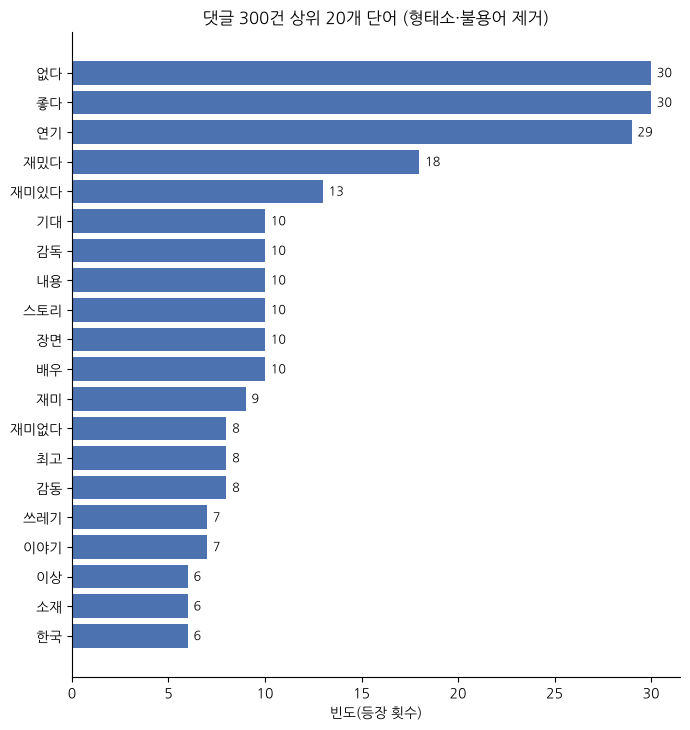

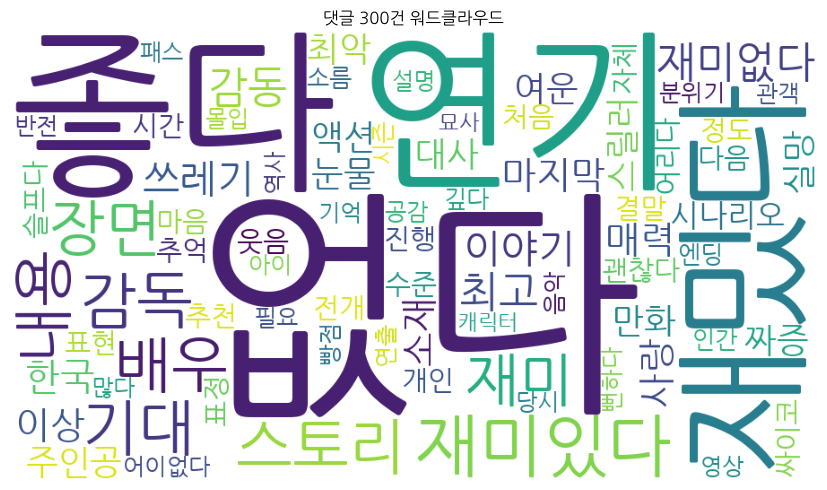

In [15]:
top_comment = pd.DataFrame(comment_cnt.most_common(30), columns=["word", "count"])
top_comment.insert(0, "rank", range(1, len(top_comment) + 1))
top_comment.to_csv("results/week07_comment_top30.csv", index=False, encoding="utf-8-sig")

bar_top(comment_cnt, "댓글 300건 상위 20개 단어 (형태소·불용어 제거)", "fig_w1_comment_bar.png")
show_wc(comment_cnt, "댓글 300건 워드클라우드", "fig_w1_comment_wc.png")

**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `pd.DataFrame(목록, columns=[…])` | (단어, 개수) 목록을 표로 |
| `insert(0, "rank", range(1, n+1))` | 맨 앞에 순위 열 추가 |
| `to_csv(…, index=False, encoding="utf-8-sig")` | CSV 저장. 엑셀에서 한글이 깨지지 않는 형식 |
| `bar_top(…), show_wc(…)` | 셀 0-9에서 만든 함수 |

## 5단계. 긍정 vs 부정 — 나눠서 비교하기
전체를 한 번에 그리면 긍정과 부정이 섞입니다. **집단을 나눠 같은 방법으로 그리면** 차이가 보입니다.
(`sentiment` 라벨은 평점에서 온 참고 라벨이라 문장과 어긋나는 경우도 있습니다.)

**▶ 셀 1-7. 긍정·부정 워드클라우드 나란히 그리기** — 실행 후 확인: 긍정 1위 `좋다 17`, 부정 1위 `없다 21`. `연기`·`좋다`는 **양쪽 모두** 상위 — 부정 댓글에도 "연기는 좋았지만…"이 많음

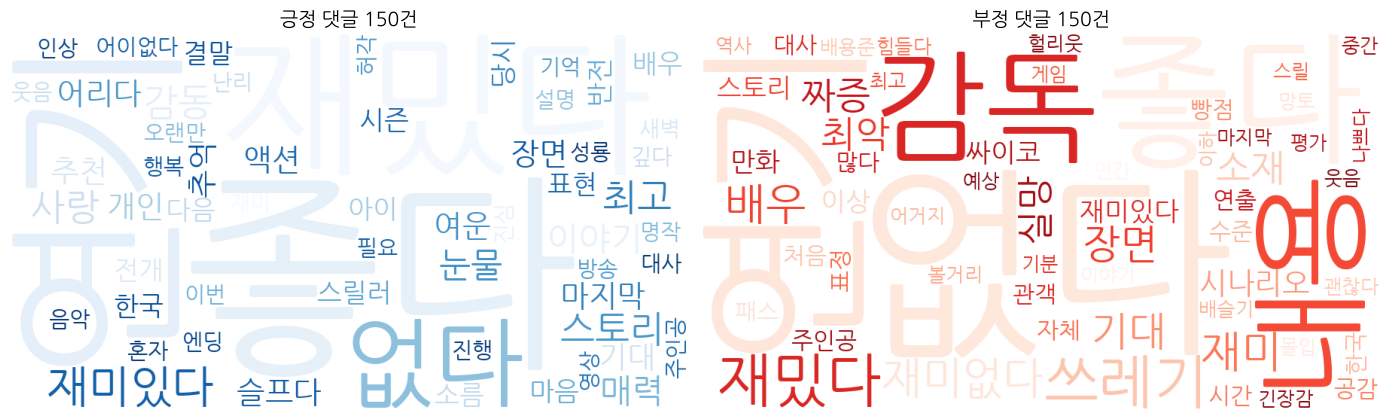

,긍정,부정
0,좋다 17,없다 21
1,연기 13,연기 16
2,재밌다 11,좋다 13
3,없다 9,감독 9
4,재미있다 9,내용 9
5,최고 6,재밌다 7
6,사랑 6,쓰레기 7
7,감동 6,재미없다 7
8,스토리 6,배우 7
9,매력 5,재미 7


In [16]:
# TODO 4: 긍정·부정 댓글을 나눠 각각 Counter를 만드세요.
#   힌트: comments.loc[comments["sentiment"] == "긍정", "tokens"]
pos_cnt = Counter(w for toks in comments.loc[comments["sentiment"] == "긍정", "tokens"] for w in toks)
neg_cnt = Counter(w for toks in comments.loc[comments["sentiment"] == "부정", "tokens"] for w in toks)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, cnt, title, cmap in [(axes[0], pos_cnt, "긍정 댓글 150건", "Blues"), (axes[1], neg_cnt, "부정 댓글 150건", "Reds")]:
    ax.imshow(make_wc(cnt, cmap, 60)); ax.axis("off"); ax.set_title(title, fontsize=14)
fig.tight_layout(); fig.savefig("figures/fig_w1_pos_neg_wc.png", dpi=150); plt.show()

pd.DataFrame({"긍정": [f"{w} {c}" for w, c in pos_cnt.most_common(10)],
              "부정": [f"{w} {c}" for w, c in neg_cnt.most_common(10)]})

**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `comments.loc[조건, "tokens"]` | 조건이 참인 행의 tokens 열만 |
| `comments["sentiment"] == "긍정"` | 행마다 True/False → 참인 행만 고르는 필터 |
| `plt.subplots(1, 2)` | 그림 칸 1행 2열 |
| `for ax, cnt, title, cmap in [(…), (…)]:` | 두 칸에 같은 코드를 반복. 값 4개를 한 번에 꺼냄 |

## 6단계. 문맥 확인 — 워드클라우드가 놓치는 것
부정 댓글 워드클라우드에서 가장 큰 글자는 `없다`이고, `재미`·`재밌다`도 보입니다. **무엇이 없다는 걸까요?**
빈도는 단어를 따로따로 세기 때문에 **부정(`재미없다`)·대조(`연기는 좋지만`)·반어**가 사라집니다.

**KWIC(Key Word In Context)**: 단어가 들어간 **원문을 직접 읽어** 문맥을 확인하는 방법입니다. 큰 단어는 반드시 원문으로 확인합니다.

확인해 보면 부정 댓글의 `재미`는 대부분 `재미없다`입니다. 형태소 분석이 `재미가 없다`를 `재미` + `없다` 둘로 나눠 버린 것입니다.
그래서 **"명사 (+조사) + 없다/있다"를 한 단어로 붙이는 규칙**을 만들어 다시 셉니다.
(`재미없네`처럼 붙여 쓴 말은 분석기가 이미 `재미없다` 한 단어로 보지만, `재미가 없다`·`재미도 없다`는 둘로 나눕니다.)

**▶ 셀 1-8. 단어가 들어간 원문 읽기 (KWIC)** — 실행 후 확인: `'재미' 포함 17건` — 표의 원문 대부분이 `재미없네`, `재미없고`, `재미도없다`

In [17]:
def kwic(word, df=comments, n=8):
    """단어가 들어간 원문 보기 (Key Word In Context)"""
    hit = df[df["text"].str.contains(word, regex=False)]
    print(f"'{word}' 포함 {len(hit)}건 (감성별 {hit['sentiment'].value_counts().to_dict()})")
    return hit[["comment_id", "sentiment", "text"]].head(n)

# TODO 5: 부정 댓글 중 '재미'가 들어간 원문을 확인하세요.  힌트: kwic("재미", comments[comments["sentiment"] == "부정"])
kwic("재미", comments[comments["sentiment"] == "부정"])

'재미' 포함 17건 (감성별 {'부정': 17})


,comment_id,sentiment,text
13,C014,부정,내용 증말 재미없네.긴장감이나 스릴감이 전혀 느켜지지 않아
41,C042,부정,보고싶긴 한데 평가가 다 나뻐서..재미있나요??
63,C064,부정,아 목소리들이 너무 좀 그럼.. 내용도 재미없고 초등생들이나 좋아할까??
71,C072,부정,열라 짜증나게 재미없네
108,C109,부정,아 재미없어... 답답하고 손현주 말하는거 짜증나고
110,C111,부정,정말 재미없개만들엇다 애니매이션영화중에 최악이다
126,C127,부정,무서움은 개뿔..게다가 재미도없다.이걸 해외로케했다니..제작비가 아까울따름..
134,C135,부정,한마디로 재미없다...


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `df["text"].str.contains(word, regex=False)` | 글자가 들어 있으면 True (정규식이 아닌 그대로의 글자) |
| `def kwic(word, df=comments, n=8):` | df·n은 기본값이 있는 입력. 다른 표나 개수를 넣을 수도 있음 |

**직접 바꿔 보기:** `kwic("최고")`, `kwic("시간")`, `kwic("연기", comments[comments["sentiment"] == "부정"])` — 빈도만 보면 틀리게 읽히는 단어를 하나 더 찾아보세요.

**▶ 셀 1-9. '명사(+조사)+없다' 붙이기 규칙으로 다시 세기** — 실행 후 확인: 규칙 후 `없다 21`이 상위에서 사라지고(5로 감소) `재미없다`가 **7 → 12**로 3위

부정 상위 10 (규칙 전): [('없다', 21), ('연기', 16), ('좋다', 13), ('감독', 9), ('내용', 9), ('재밌다', 7), ('쓰레기', 7), ('재미없다', 7), ('배우', 7), ('재미', 7)]
부정 상위 10 (규칙 후): [('연기', 16), ('좋다', 13), ('재미없다', 12), ('감독', 9), ('내용', 9), ('재밌다', 7), ('쓰레기', 7), ('배우', 7), ('기대', 6), ('장면', 6)]


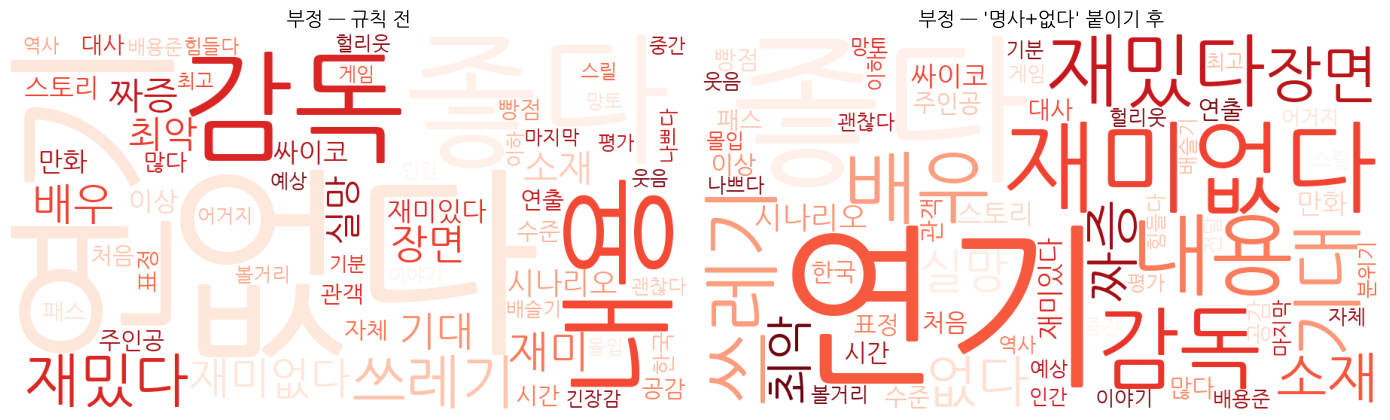

In [18]:
def morph_tokens_v2(text):
    """명사 뒤에 (조사를 건너뛰고) '없/있'이 오면 한 단어로 붙인다: 재미+없다, 재미+가+없다 → '재미없다'"""
    toks = kiwi.tokenize(str(text)); out = []; i = 0
    while i < len(toks):
        t = toks[i]
        j = i + 1
        while j < len(toks) and toks[j].tag.startswith("J"):     # 조사(J로 시작하는 품사) 건너뛰기
            j += 1
        if t.tag == "NNG" and j < len(toks) and toks[j].tag == "VA" and toks[j].form in ("없", "있"):
            out.append(t.form + toks[j].form + "다"); i = j + 1; continue
        if t.tag in ("NNG", "NNP") and len(t.form) >= 2:
            out.append(t.form)
        elif t.tag == "VA":
            out.append(t.form + "다")
        i += 1
    return [w for w in out if w not in STOP_COMMENT]

neg_cnt_v2 = Counter(w for t in comments.loc[comments["sentiment"] == "부정", "text"] for w in morph_tokens_v2(t))
print("부정 상위 10 (규칙 전):", neg_cnt.most_common(10))
print("부정 상위 10 (규칙 후):", neg_cnt_v2.most_common(10))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, cnt, title in [(axes[0], neg_cnt, "부정 — 규칙 전"), (axes[1], neg_cnt_v2, "부정 — '명사+없다' 붙이기 후")]:
    ax.imshow(make_wc(cnt, "Reds", 60)); ax.axis("off"); ax.set_title(title, fontsize=14)
fig.tight_layout(); fig.savefig("figures/fig_w1_negation_fix.png", dpi=150); plt.show()

**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `while 조건:` | 조건이 참인 동안 반복. 직접 i를 늘려야 함 |
| `toks[j].tag.startswith("J")` | 품사가 J(조사)로 시작하면 |
| `continue` | 반복의 나머지를 건너뛰고 다음 차례로 |
| `i = j + 1` | 붙인 두 형태소를 모두 처리했으니 그 다음부터 |

**직접 바꿔 보기:** 규칙이 만든 단어 목록 `[w for w in neg_cnt_v2 if w.endswith("없다")]`을 보세요. `자체없다`처럼 어색한 것도 생깁니다 — 규칙도 완벽하지 않습니다.

**워크북 1 기록 (제출 문서에 작성)**
1. 어절과 형태소 방식의 상위 단어가 어떻게 달랐는가? (2~3문장)
2. 내가 추가한 불용어와 그 이유
3. 긍정/부정 워드클라우드의 차이 3가지
4. 빈도만으로 틀리게 읽히는 단어 하나 더 찾기 → `kwic()` 결과 2건 인용

---
# 워크북 2 · 뉴스 기사 제목 워드클라우드
**목표** 뉴스 제목의 명사 빈도를 **전체 → 분야별**로 시각화하고, **빈도 상위 = 그 분야의 특징**이 아님을 TF-IDF로 확인한다.

## 1단계. 뉴스 제목 불러오고 분야별 건수 보기
| 열 | 뜻 |
|---|---|
| `news_id` | N001~N350 수업용 번호 |
| `category` | 분야 7개: 정치·경제·사회·생활문화·세계·IT과학·스포츠 (KLUE 작업자가 붙인 라벨) |
| `title` | 기사 제목 — 본문은 없음. KLUE가 따옴표 등 일부 기호를 지워 `…종합`, `1보`가 붙어 보임 |
| `date`, `url` | 기사 날짜(2016~2019년), 네이버 뉴스 주소(일부는 삭제됐을 수 있음) |

분야마다 50건씩 **같은 수**를 뽑았기 때문에 분야끼리 공정하게 비교할 수 있습니다(층화 추출).

**▶ 셀 2-1. 뉴스 CSV 읽고 분야별 건수 세기** — 실행 후 확인: 350행 × 6열 · 2016-01-07 ~ 2019-12-31 · 7개 분야 각 50

In [19]:
news = pd.read_csv(io.BytesIO(check_file("week07_news_350.csv")), encoding="utf-8-sig")
print("행·열:", news.shape, "| 기간:", news["date"].min(), "~", news["date"].max())

# TODO 6: 분야(category)별 기사 수를 세세요.  힌트: news["category"].value_counts()
news["category"].value_counts()

week07_news_350.csv         71,235 bytes → 정상(MD5 일치)
행·열: (350, 6) | 기간: 2016-01-07 ~ 2019-12-31


category
정치      50
IT과학    50
생활문화    50
세계      50
스포츠     50
사회      50
경제      50
Name: count, dtype: int64

**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `check_file(…)를 read_csv 안에 바로` | 읽기·확인·표 만들기를 한 줄로 |
| `news["date"].min(), .max()` | 가장 이른·늦은 날짜 (YYYY-MM-DD 문자열은 글자 순서 = 날짜 순서) |

**▶ 셀 2-2. 제목 몇 개 읽어 보기** — 실행 후 확인: N001 정치 `박주선 정부 공무원 배치계획 따라 예비비 동의여부 결정` 등 8행

In [20]:
news[["news_id", "category", "title", "date"]].head(8)

,news_id,category,title,date
0,N001,정치,박주선 정부 공무원 배치계획 따라 예비비 동의여부 결정,2017-07-21
1,N002,IT과학,삼성 23일 갤노트10 70개국 출시…9월 130개국으로 확대,2019-08-22
2,N003,생활문화,연천 영하 19.1도…경기북부 오후부터 강추위 풀려,2018-01-30
3,N004,세계,민주콩고서 폭우로 인한 잇단 산사태로 13명 숨져,2019-04-30
4,N005,생활문화,팩트체크 프레디 머큐리는 정말 공항서 수하물을 날랐나,2018-12-04
5,N006,스포츠,맨유 린가드와 2021년까지 재계약…주급 1억4천만원까지 예상,2017-04-07
6,N007,IT과학,다산네트웍스 차세대 모바일 백홀 표준인증 획득,2016-06-28
7,N008,사회,유방암·조현병 영향 단백질 제한 방법 발견,2016-09-21


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `news[[열1, 열2, …]]` | 여러 열만 골라 보기 |

**직접 바꿔 보기:** `news[news["category"] == "IT과학"].head()`로 한 분야만 골라 읽어 보세요.

## 2단계. 명사 빈도 — 뉴스용 불용어
뉴스 제목에는 `종합`, `1보`, `게시판`, `포토`처럼 **기사 형식**을 나타내는 말과 `오늘`, `올해`처럼 날짜를 가리키는 말이 붙습니다.
내용이 아니므로 불용어로 뺍니다. 뉴스는 명사가 주제를 잘 나타내므로 **명사만** 셉니다.

**▶ 셀 2-3. 명사만 세기 → 빈도표·막대·워드클라우드** — 실행 후 확인: 상위 `대통령 15` `정부 11` `개발 9` `한국 8` `이란 8` … `감독`(스포츠 감독)·`최고`(최고 기온·역대 최고)처럼 뜻이 섞인 말도 보임

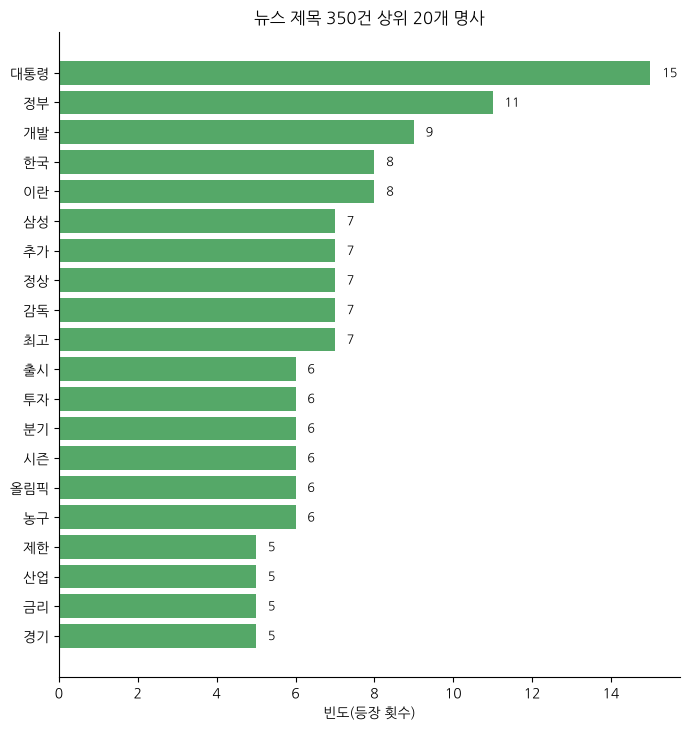

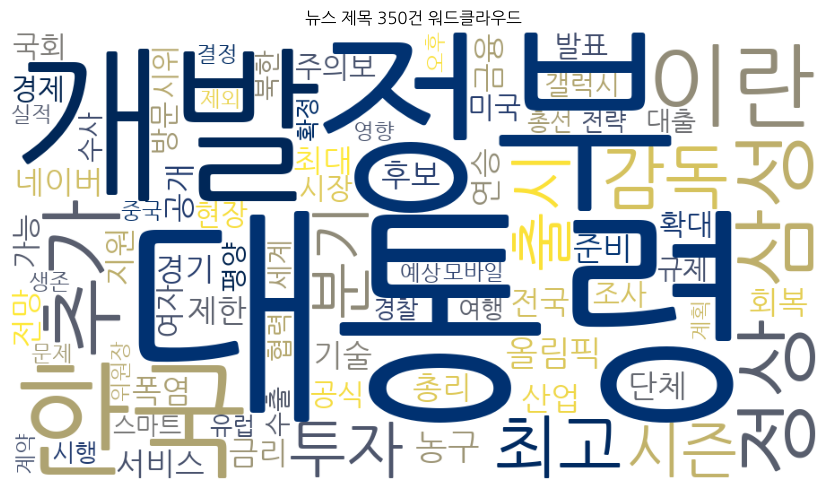

In [21]:
STOP_NEWS = {"종합", "속보", "1보", "2보", "3보", "게시판", "그래픽", "신간", "오늘", "내일", "올해", "작년", "단독", "포토"}

def news_tokens(text):
    return [t.form for t in kiwi.tokenize(str(text))
            if t.tag in ("NNG", "NNP") and len(t.form) >= 2 and t.form not in STOP_NEWS]

news["tokens"] = news["title"].apply(news_tokens)
news_cnt = Counter(w for toks in news["tokens"] for w in toks)

top_news = pd.DataFrame(news_cnt.most_common(30), columns=["word", "count"])
top_news.insert(0, "rank", range(1, len(top_news) + 1))
top_news.to_csv("results/week07_news_top30.csv", index=False, encoding="utf-8-sig")
bar_top(news_cnt, "뉴스 제목 350건 상위 20개 명사", "fig_w2_news_bar.png", color="#55A868")
show_wc(news_cnt, "뉴스 제목 350건 워드클라우드", "fig_w2_news_wc.png", colormap="cividis")

**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `[t.form for t in … if 조건1 and 조건2 and 조건3]` | 명사이고, 2글자 이상이고, 불용어가 아닌 것만 |
| `color="#55A868"` | 막대 색(16진수 색상 코드) |

## 3단계. 분야별 워드클라우드
전체 워드클라우드는 7개 분야가 섞여 각 분야의 주제가 흐려집니다. **분야별로 나눠 같은 방법으로** 그리면 주제가 드러납니다(워크북 1의 긍정/부정 비교와 같은 방법).

**▶ 셀 2-4. 분야 7개 워드클라우드 한 장에 그리기** — 실행 후 확인: 분야별 1위: 정치 `대통령` · 경제 `투자` · 사회 `단체` · 생활문화 `폭염` · 세계 `정부` · IT과학 `개발` · 스포츠 `감독`

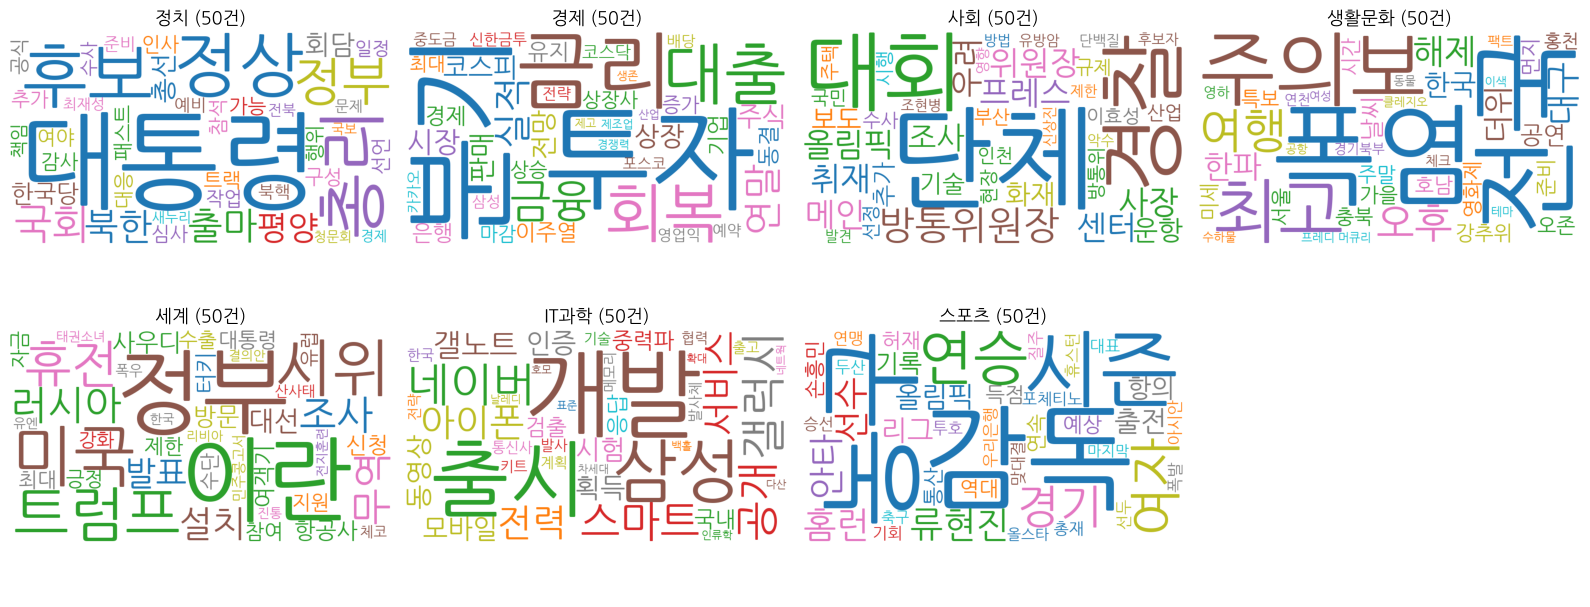

,정치,경제,사회,생활문화,세계,IT과학,스포츠
0,대통령,투자,단체,폭염,정부,개발,감독
1,정상,분기,대회,전국,이란,출시,농구
2,후보,금리,경찰,주의보,미국,삼성,시즌
3,총리,대출,방통위원장,최고,시위,네이버,연승
4,정부,회복,사장,여행,트럼프,갤럭시,여자


In [22]:
CATS = ["정치", "경제", "사회", "생활문화", "세계", "IT과학", "스포츠"]
# TODO 7: 분야별 Counter를 dict로 만드세요.  힌트: {c: Counter(w for toks in news.loc[news["category"] == c, "tokens"] for w in toks) for c in CATS}
cat_cnt = {c: Counter(w for toks in news.loc[news["category"] == c, "tokens"] for w in toks) for c in CATS}

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, c in zip(axes.flat, CATS):
    ax.imshow(make_wc(cat_cnt[c], "tab10", 40)); ax.axis("off"); ax.set_title(f"{c} (50건)", fontsize=13)
axes.flat[-1].axis("off")                     # 8칸 중 마지막 빈칸 숨기기
fig.tight_layout(); fig.savefig("figures/fig_w2_category_wc.png", dpi=150); plt.show()
pd.DataFrame({c: [w for w, _ in cat_cnt[c].most_common(5)] for c in CATS})

**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `{c: … for c in CATS}` | 딕셔너리 컴프리헨션: 분야 이름 → 그 분야의 Counter |
| `plt.subplots(2, 4)` | 2행 4열 = 8칸 (분야는 7개) |
| `zip(axes.flat, CATS)` | 칸과 분야를 하나씩 짝지음 |

## 4단계. 빈도 vs 특징어 (TF-IDF)
빈도 1위가 곧 **그 분야만의 특징**은 아닙니다. `정부`는 정치·경제·세계 어디에나 나옵니다.

**TF-IDF** = TF(이 분야에서 얼마나 자주 나오나) × IDF(다른 분야에는 얼마나 드문가).
**여러 분야에 두루 나오는 말은 점수가 낮아지고, 이 분야에만 몰려 나오는 말은 높아집니다.**

| 질문 | 쓰는 것 |
|---|---|
| "이 분야에서 가장 많이 나온 말은?" | 빈도 |
| "이 분야를 다른 분야와 구별하는 말은?" | TF-IDF |

여기서는 **분야 1개 = 문서 1개**로 보고(문서 7개), 각 분야에서 TF-IDF 점수가 높은 단어 5개를 뽑습니다.

**▶ 셀 2-5. 분야별 빈도 상위 5 vs TF-IDF 상위 5** — 실행 후 확인: 세계 1위가 `정부`(빈도) → `이란`(TF-IDF). 정치에 `출마`·`회담`, 경제에 `금융`, IT과학에 `스마트`, 사회에 `프레스`가 새로 들어옴

In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer

docs = [" ".join(w for toks in news.loc[news["category"] == c, "tokens"] for w in toks) for c in CATS]  # 분야 1개 = 문서 1개
tfidf = TfidfVectorizer(token_pattern=r"\S+")          # 이미 나눈 단어(공백 구분)를 그대로 사용
X = tfidf.fit_transform(docs).toarray()                # 7행(분야) × 단어 수 열의 점수표
vocab = np.array(tfidf.get_feature_names_out())
tfidf_top = pd.DataFrame({c: vocab[X[i].argsort()[::-1][:5]] for i, c in enumerate(CATS)})
freq_top = pd.DataFrame({c: [w for w, _ in cat_cnt[c].most_common(5)] for c in CATS})
print("[빈도 상위 5]"); display(freq_top)
print("[TF-IDF 특징어 상위 5]"); display(tfidf_top)

[빈도 상위 5]


,정치,경제,사회,생활문화,세계,IT과학,스포츠
0,대통령,투자,단체,폭염,정부,개발,감독
1,정상,분기,대회,전국,이란,출시,농구
2,후보,금리,경찰,주의보,미국,삼성,시즌
3,총리,대출,방통위원장,최고,시위,네이버,연승
4,정부,회복,사장,여행,트럼프,갤럭시,여자


[TF-IDF 특징어 상위 5]


,정치,경제,사회,생활문화,세계,IT과학,스포츠
0,대통령,분기,대회,폭염,이란,개발,감독
1,후보,투자,방통위원장,전국,정부,출시,농구
2,총리,금리,경찰,주의보,트럼프,갤럭시,연승
3,출마,대출,단체,여행,미국,스마트,시즌
4,회담,금융,프레스,해제,시위,네이버,여자


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `" ".join(단어들)` | 단어 목록을 공백으로 이어 한 문자열(문서)로 |
| `TfidfVectorizer(token_pattern=r"\S+")` | 공백이 아닌 덩어리를 단어로 봄 = 우리가 나눈 단어 그대로 |
| `fit_transform(docs).toarray()` | 단어 목록을 만들고(fit) 점수표로 바꿈(transform) |
| `X[i].argsort()[::-1][:5]` | i번째 분야 점수를 큰 순서로 정렬했을 때의 위치 5개 |
| `display(표)` | 셀 중간에서도 표를 보기 좋게 출력 |

**워크북 2 기록 (제출 문서에 작성)**
1. 전체 vs 분야별 워드클라우드 — 보이는 것의 차이
2. 뉴스 불용어로 뺀 단어와 이유 (하나 이상 직접 추가해 보기)
3. 빈도 상위와 TF-IDF 상위가 다른 분야 하나와 그 이유
4. 이 제목들은 2016~2019년 자료입니다. 같은 방법을 오늘 뉴스에 쓰면 무엇이 달라질까요?

---
# 워크북 3 · AI 요약·키워드와 비교·검증
**목표** 같은 원문으로 AI 요약·키워드를 받아 **원문 근거 건수 · 빈도 순위 · 원문 대조**로 검증하고, 워드클라우드(빈도)와의 일치·차이·한계를 정리한다.

## 1단계. AI에게 줄 프롬프트 만들기
워드클라우드는 **세는 것**, AI 요약·키워드는 **읽고 해석하는 것**입니다. 두 결과를 공정하게 비교하려면 **같은 원문 전체**를 AI에게 줘야 합니다.

좋은 프롬프트의 조건:
- **근거를 원문으로 한정**: "아래 원문만 근거로, 없는 내용은 추측하지 마세요"
- **형식 지정**: 요약 3문장 · 키워드 5개 · 키워드마다 근거 원문 번호 2개 → 나중에 번호로 검증 가능
- **번호 붙인 원문**: `C001 …`, `N001 …` → AI가 근거를 번호로 댈 수 있음

**▶ 셀 3-1. 원문 전체가 들어간 프롬프트 만들어 저장** — 실행 후 확인: `댓글 프롬프트 12,496자 · 뉴스 프롬프트 11,845자` + 지시문과 `C001 폴워커의 …` 시작 부분

In [24]:
PROMPT_HEAD = """다음은 {label} {n}건입니다. 아래 원문만 근거로 답하세요. 원문에 없는 내용은 추측하지 마세요.
1) 전체 내용을 3문장으로 요약
2) 핵심 키워드 5개 (원문에 실제로 나오는 낱말 위주)
3) 각 키워드마다 근거가 되는 원문 번호 2개
형식:
요약: ...
키워드: 단어1, 단어2, 단어3, 단어4, 단어5
근거: 단어1-번호,번호 / 단어2-번호,번호 / ...
---
"""

def make_prompt(df, id_col, text_col, label):
    body = "\n".join(f"{i} {t}" for i, t in zip(df[id_col], df[text_col]))
    return PROMPT_HEAD.format(label=label, n=len(df)) + body

prompt_comment = make_prompt(comments, "comment_id", "text", "영화 관람객 댓글")
prompt_news = make_prompt(news, "news_id", "title", "뉴스 기사 제목")
open("results/prompt_comments.txt", "w", encoding="utf-8").write(prompt_comment)
open("results/prompt_news.txt", "w", encoding="utf-8").write(prompt_news)
print(f"댓글 프롬프트 {len(prompt_comment):,}자 · 뉴스 프롬프트 {len(prompt_news):,}자 → results/ 폴더에 저장")
print(prompt_comment[:500], "\n...(이하 생략)")

댓글 프롬프트 12,496자 · 뉴스 프롬프트 11,845자 → results/ 폴더에 저장
다음은 영화 관람객 댓글 300건입니다. 아래 원문만 근거로 답하세요. 원문에 없는 내용은 추측하지 마세요.
1) 전체 내용을 3문장으로 요약
2) 핵심 키워드 5개 (원문에 실제로 나오는 낱말 위주)
3) 각 키워드마다 근거가 되는 원문 번호 2개
형식:
요약: ...
키워드: 단어1, 단어2, 단어3, 단어4, 단어5
근거: 단어1-번호,번호 / 단어2-번호,번호 / ...
---
C001 폴워커의 유작이라 기대됨 근데 개봉관이 왜 없??
C002 내가유일하게싫어하는왕가위영화..국영이형죄송ㅋ
C003 빨간 망토의 현대적 재해석은 커녕 늑대인간 컨셉을 어거지로 끼워 맞춘 하이틴 로맨스, 딱 이 감독의 전작인 트와일라잇 수준의 영화... 백설 속의 빨간 망토 이미지만이 도드라지고 내용은 패륜과 막장 드라마
C004 도통 무슨내용인지..지금 보고있는데 잠만오는듯..
C005 화끈한 액션이 볼만함
C006 스릴이 부실하면 볼거리라도 있어야지
C007 무서운 영화였어. 그리고 두 남매가  
...(이하 생략)


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `"""여러 줄 문자열"""` | 따옴표 세 개: 줄바꿈을 그대로 담는 문자열 |
| `PROMPT_HEAD.format(label=…, n=…)` | 문자열 안의 `{label}`, `{n}` 자리에 값을 채움 |
| `"\n".join(…)` | 줄바꿈으로 이어 붙이기 → 한 줄에 원문 하나 |
| `zip(df[id_col], df[text_col])` | 번호와 원문을 짝지어 하나씩 |

**▶ 셀 3-2. 프롬프트 전체 출력 (복사할 때만)** — 실행 후 확인: 출력 없음(주석). 복사할 때 `#`을 지우고 실행

In [25]:
# 필요할 때만 # 를 지우고 실행해서 출력 전체를 복사 → AI 새 대화에 붙여 넣기
# print(prompt_comment)
# print(prompt_news)
# 또는 왼쪽 📁 창 results/prompt_comments.txt 를 내려받아 열기

**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `# 코드` | 주석이라 실행되지 않음. `#`을 지우면 실행됨 |

## 2단계. AI 결과 붙여 넣기
AI 답의 **요약**과 **키워드 5개**를 노트북 변수에 옮겨 적습니다. 완성본에는 **예시 결과**(Claude, 2026-10-15)가 들어 있습니다 —
**여러분이 받은 결과로 바꿔서** 검증하세요.

**▶ 셀 3-3. AI 요약·키워드 붙여 넣기** — 실행 후 확인: 키워드 목록 두 줄. 실습본은 `"..."`를 내 AI 결과로 바꾸지 않으면 다음 셀에서 근거 0건으로 나옴

In [26]:
AI_NAME = "Claude (예시, 2026-10-15)"      # 사용한 AI 이름과 날짜로 바꾸기
ai_comment_summary = """1) 댓글은 긍정과 부정이 반반으로, 긍정 댓글은 배우의 연기와 감동·눈물, 다시 보고 싶을 만큼의 재미를 칭찬한다(C115, C062).
2) 부정 댓글은 지루함, 뻔하거나 억지스러운 줄거리, 시간·돈이 아깝다는 불만이 중심이다(C169, C205).
3) 연기는 좋지만 내용이 아쉽다는 엇갈린 평가와, 평점이 너무 높거나 낮다는 평점 불신도 자주 보인다(C148, C071)."""
ai_comment_keywords = ["연기", "감동", "재미", "지루", "평점"]
ai_news_summary = """1) 2016~2019년 기사 제목으로 정치·경제·사회·생활문화·세계·IT과학·스포츠 7개 분야가 고르게 섞여 있다.
2) 정치·세계 분야는 대통령과 정상회담, 북한, 미국·이란 등 국제 갈등을, 경제·IT과학 분야는 코스피·금리와 스마트폰 출시를 주로 다룬다(N125, N089, N002).
3) 생활문화는 폭염·한파 등 날씨, 스포츠는 류현진 등 해외 리그 한국 선수와 프로농구 소식이 많다(N072, N040)."""
ai_news_keywords = ["대통령", "북한", "스마트폰", "코스피", "폭염"]
print("댓글 AI 키워드:", ai_comment_keywords)
print("뉴스 AI 키워드:", ai_news_keywords)

댓글 AI 키워드: ['연기', '감동', '재미', '지루', '평점']
뉴스 AI 키워드: ['대통령', '북한', '스마트폰', '코스피', '폭염']


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `["연기", "감동", …]` | 리스트: 따옴표로 감싼 문자열 5개를 쉼표로 |
| `"""…"""` | 요약은 여러 줄이라 따옴표 세 개로 감쌈 |

## 3단계. AI 키워드 검증 — 근거 건수와 빈도 순위
AI 키워드마다 세 가지를 확인합니다.

| 확인 | 방법 | 결과 해석 |
|---|---|---|
| ① 근거 건수 | 키워드가 들어간 원문이 몇 건인가 | **0건** → 원문에 없는 말(AI가 바꿔 말했거나 만들어 냄) |
| ② 빈도 순위 | 워크북 1·2 빈도표에서 몇 위인가 | `-` → 빈도표에 없음: 불용어로 뺐거나(`평점`) 형태소 분석이 다르게 자름(`지루`→`지루하다`) |
| ③ 원문 예시 | 실제로 들어간 문장 읽기 | `재미` 30건에는 `재미없다`도 섞임 → **건수가 많다고 긍정 근거는 아님** |

**▶ 셀 3-4. 키워드마다 근거 건수·빈도 순위·원문 예시** — 실행 후 확인: (예시 기준) 근거 0건 없음 · `연기` 24건·3위 · `재미` 30건·12위(원문예시가 `재미없네`) · `지루`·`평점`은 빈도표에 없음 · `대통령` 15건·1위 · `스마트폰` 2건·326위

In [27]:
def verify_keywords(keywords, df, text_col, id_col, counter, label):
    rank = {w: i + 1 for i, (w, _) in enumerate(counter.most_common())}
    rows = []
    for k in keywords:
        hit = df[df[text_col].str.contains(k, regex=False)]
        r = rank.get(k)
        rows.append({"자료": label, "AI키워드": k, "근거건수": len(hit),
                     "빈도순위": r if r else "-",
                     "판정": ("근거 없음" if len(hit) == 0 else "빈도 상위10" if r and r <= 10
                               else "근거 있음·빈도 하위" if r else "근거 있음·빈도표에 없음"),
                     "원문예시": (hit[id_col].iloc[0] + " " + hit[text_col].iloc[0][:40]) if len(hit) else ""})
    return pd.DataFrame(rows)

check = pd.concat([verify_keywords(ai_comment_keywords, comments, "text", "comment_id", comment_cnt, "댓글"),
                   verify_keywords(ai_news_keywords, news, "title", "news_id", news_cnt, "뉴스")], ignore_index=True)
check.to_csv("results/week07_ai_keyword_check.csv", index=False, encoding="utf-8-sig")
check

,자료,AI키워드,근거건수,빈도순위,판정,원문예시
0,댓글,연기,24,3,빈도 상위10,C009 집에서 따뜻해지기 좋은영화. 이연희랑 역할도 잘어울리고 연기도 좋았슴 전
1,댓글,감동,8,15,근거 있음·빈도 하위,C062 진짜 편한 마음으로 봤는데 내 눈물까지 본 영화 ㅜㅜ감동적이고 계속 더
2,댓글,재미,30,12,근거 있음·빈도 하위,C014 내용 증말 재미없네.긴장감이나 스릴감이 전혀 느켜지지 않아
3,댓글,지루,9,-,근거 있음·빈도표에 없음,C036 특별한건 없지만 그것이 매력인 영화인거 같아요. 소박하면서도 꾸며지지 않
4,댓글,평점,10,-,근거 있음·빈도표에 없음,C026 몸만 어른인 청춘들의 객기만을 보는듯.... 평점이 넘 높네
5,뉴스,대통령,15,1,빈도 상위10,N078 靑 대통령 겨냥했다 판단…각종 의혹에 단호대응
6,뉴스,북한,4,54,근거 있음·빈도 하위,N083 북한 건군절 70주년 기념 열병식
7,뉴스,스마트폰,2,326,근거 있음·빈도 하위,N243 삼성·LG 연말 스마트폰 시장 한정판·명품 마케팅
8,뉴스,코스피,3,116,근거 있음·빈도 하위,N089 코스피 상승 마감…2010선 회복1보
9,뉴스,폭염,5,21,근거 있음·빈도 하위,N025 폭염도시 대구 온열 질환자가 전국에서 가장 적은 이유는


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `{w: i + 1 for i, (w, _) in enumerate(…)}` | 단어 → 순위 사전. enumerate는 0부터 번호를 붙임 |
| `rank.get(k)` | 사전에 없으면 None(오류 아님) |
| `A if 조건1 else B if 조건2 else C` | 조건 여러 개를 이어 쓴 조건 표현식 |
| `hit[id_col].iloc[0]` | 찾은 행 중 첫 번째의 번호 |
| `pd.concat([표1, 표2], ignore_index=True)` | 두 표를 위아래로 이어 붙이고 행 번호를 새로 |

## 4단계. 빈도 상위 10 vs AI 키워드 — 일치와 차이
**집합 연산**으로 두 결과를 비교합니다: 둘 다 고른 단어(교집합), AI만 고른 단어, 빈도에만 있는 단어(차집합).
그리고 워드클라우드 위에 AI 키워드만 빨간색으로 칠해 **빈도와 AI 판단이 어디서 겹치는지** 봅니다.

**▶ 셀 3-5. 교집합·차집합으로 비교** — 실행 후 확인: (예시 기준) 일치 댓글 1개(`연기`), 뉴스 1개(`대통령`). AI만: `감동·재미·지루·평점`, `북한·스마트폰·코스피·폭염`

In [28]:
# TODO 9: 빈도 상위 10개 단어 집합과 AI 키워드 집합의 교집합·차집합을 구하세요.
#   힌트: set(w for w, _ in comment_cnt.most_common(10)) & set(ai_comment_keywords)
def overlap(counter, keywords, label):
    freq10 = set(w for w, _ in counter.most_common(10))
    ai = set(keywords)
    return {"자료": label, "둘 다": sorted(freq10 & ai), "AI만": sorted(ai - freq10),
            "빈도만": sorted(freq10 - ai), "일치 개수": len(freq10 & ai)}

pd.DataFrame([overlap(comment_cnt, ai_comment_keywords, "댓글"), overlap(news_cnt, ai_news_keywords, "뉴스")])

,자료,둘 다,AI만,빈도만,일치 개수
0,댓글,[연기],"[감동, 재미, 지루, 평점]","[감독, 기대, 내용, 스토리, 없다, 장면, 재미있다, 재밌다, 좋다]",1
1,뉴스,[대통령],"[북한, 스마트폰, 코스피, 폭염]","[감독, 개발, 삼성, 이란, 정부, 정상, 최고, 추가, 한국]",1


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `set(…)` | 집합으로 바꾸기 |
| `A & B` | 교집합: 둘 다 있는 것 |
| `A - B` | 차집합: A에만 있는 것 |
| `sorted(집합)` | 가나다순 목록으로 |

**▶ 셀 3-6. 워드클라우드 위에 AI 키워드 표시** — 실행 후 확인: 빨간 글자가 크면 빈도와 AI가 일치, 작거나 없으면 AI가 빈도가 낮은 말을 고른 것

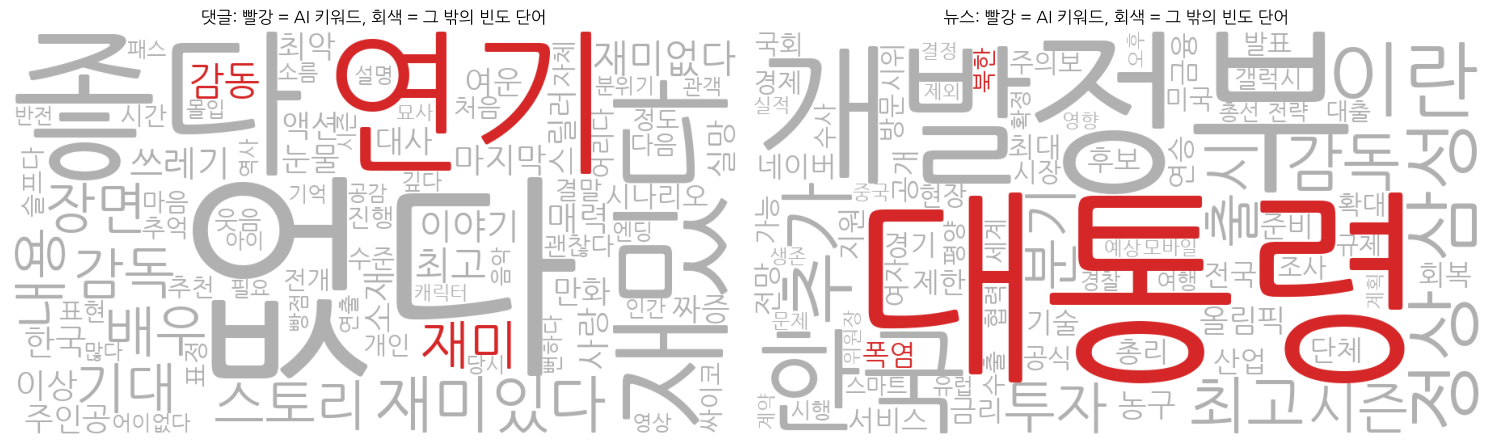

In [29]:
def highlight(keywords):
    ks = set(keywords)
    return lambda word, **kw: "#D62728" if word in ks else "#B0B0B0"   # AI 키워드면 빨강, 아니면 회색

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, cnt, ks, title in [(axes[0], comment_cnt, ai_comment_keywords, "댓글"), (axes[1], news_cnt, ai_news_keywords, "뉴스")]:
    ax.imshow(make_wc(cnt).recolor(color_func=highlight(ks), random_state=42)); ax.axis("off")
    ax.set_title(f"{title}: 빨강 = AI 키워드, 회색 = 그 밖의 빈도 단어", fontsize=12)
fig.tight_layout(); fig.savefig("figures/fig_w3_ai_overlay.png", dpi=150); plt.show()

**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `lambda word, **kw: …` | 이름 없는 짧은 함수. 워드클라우드가 단어마다 불러 색을 정함 |
| `make_wc(cnt).recolor(color_func=…)` | 같은 배치에 색만 다시 칠함 |

## 5단계. AI 요약 문장 확인 — 근거 번호의 원문 읽기
AI가 댄 근거 번호가 **실제 원문 번호이더라도 내용이 주장과 다를 수 있습니다**.
(이 자료를 만들 때도 예시 답에서 "연기는 좋지만 내용이 아쉽다"의 근거로 댄 번호가 실제로는 연기를 비판하는 댓글이어서 고쳤습니다.)
요약 문장마다 근거 번호를 열어 읽고 **O / X / 일부**로 판정해 검증 기록지에 적습니다.

**▶ 셀 3-7. 근거 번호의 원문 열어 보기** — 실행 후 확인: 요약 3문장과 근거 원문 4건. 각 원문이 요약의 주장(연기 칭찬·감동, 지루함·시간 아까움)과 맞는지 읽어 보기

In [30]:
def show_ids(ids, df=comments, id_col="comment_id", text_col="text"):
    return df[df[id_col].isin(ids)][[id_col, text_col]]

print(ai_comment_summary)
show_ids(["C115", "C062", "C169", "C205"])        # AI 답변의 '근거' 번호로 바꿔서 확인

1) 댓글은 긍정과 부정이 반반으로, 긍정 댓글은 배우의 연기와 감동·눈물, 다시 보고 싶을 만큼의 재미를 칭찬한다(C115, C062).
2) 부정 댓글은 지루함, 뻔하거나 억지스러운 줄거리, 시간·돈이 아깝다는 불만이 중심이다(C169, C205).
3) 연기는 좋지만 내용이 아쉽다는 엇갈린 평가와, 평점이 너무 높거나 낮다는 평점 불신도 자주 보인다(C148, C071).


,comment_id,text
61,C062,진짜 편한 마음으로 봤는데 내 눈물까지 본 영화 ㅜㅜ감동적이고 계속 더 봐도 마음 훈훈해질것 같아요....
114,C115,최민식의 연기가 압권이었다.소재는 뻔하지만 극전개 분위기도 좋고 여운도 남구.
168,C169,지루해둑는줄. 과정뻔해 결과뻔해.
204,C205,이거 재밌다는 사람은 스릴러 처음 봤음? 너무 엉성한 시나리오. 맥 빠지는 연출력. 개연성 없는 전후...


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `df[id_col].isin(ids)` | 번호가 목록 안에 있으면 True |
| `show_ids(…, df=news, id_col="news_id", text_col="title")` | 뉴스 근거를 볼 때 |

**직접 바꿔 보기:** 뉴스 요약의 근거도 `show_ids(["N125", "N089"], df=news, id_col="news_id", text_col="title")`로 확인하세요.

## 6단계. 결과 내려받기와 정리
`results/`(CSV 3개·프롬프트 2개)와 `figures/`(그림 8장)를 zip으로 묶어 내려받아 제출합니다.

| 기준 | 워드클라우드(빈도) | AI 요약·키워드 | 내 관찰 |
|---|---|---|---|
| 무엇을 근거로 | 단어 등장 횟수 | 문장의 의미·문맥 | |
| 재현성 | 같은 입력이면 항상 같음 | 매번 다름, AI·날짜마다 다름 | |
| 잘한 점 | 숫자로 확인 가능 | 부정·대조를 읽고 문장으로 요약 | |
| 한계 | 문맥·부정 손실, 토큰화·불용어 영향 | 원문에 없는 말, 근거 번호 오류 가능 | |
| 일치한 키워드 | | | |

**▶ 셀 3-8. 결과 zip 만들어 내려받기** — 실행 후 확인: results 5개(CSV 3·프롬프트 2), figures 9개(그림 8 + 시험 막대그래프) 목록, 브라우저에서 zip 2개 다운로드

In [31]:
import shutil
shutil.make_archive("week07_results", "zip", ".", "results")
shutil.make_archive("week07_figures", "zip", ".", "figures")
print(sorted(os.listdir("results")), sorted(os.listdir("figures")), sep="\n")
try:
    from google.colab import files
    files.download("week07_results.zip"); files.download("week07_figures.zip")
except ImportError:
    print("Colab이 아니므로 다운로드 창은 생략 (zip 파일은 현재 폴더에 있음)")

['prompt_comments.txt', 'prompt_news.txt', 'week07_ai_keyword_check.csv', 'week07_comment_top30.csv', 'week07_news_top30.csv']
['fig_w1_comment_bar.png', 'fig_w1_comment_wc.png', 'fig_w1_negation_fix.png', 'fig_w1_pos_neg_wc.png', 'fig_w2_category_wc.png', 'fig_w2_news_bar.png', 'fig_w2_news_wc.png', 'fig_w3_ai_overlay.png', 'test_bar.png']
Colab이 아니므로 다운로드 창은 생략 (zip 파일은 현재 폴더에 있음)


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `shutil.make_archive(이름, "zip", 기준폴더, 묶을폴더)` | 폴더를 zip 파일로 묶기 |
| `files.download(파일)` | Colab에서 내 컴퓨터로 내려받기 |

**▶ 셀 3-9. [선택] Colab 안에서 AI 직접 호출** — 실행 후 확인: `건너뜀`. 계정에 따라 Colab AI(Gemini 등)를 키 없이 쓸 수 있으며, 안 되면 3-1의 복사 방식으로 진행

In [32]:
RUN_COLAB_AI = False        # True로 바꾸고 실행
if RUN_COLAB_AI:
    try:
        from google.colab import ai
        print("사용 가능한 모델:", ai.list_models())
        print(ai.generate_text(prompt_comment))
    except Exception as e:
        print("Colab AI를 사용할 수 없습니다 → 프롬프트 복사 방식으로 진행하세요:", type(e).__name__, e)
else:
    print("건너뜀: RUN_COLAB_AI = True 로 바꾸면 실행")

건너뜀: RUN_COLAB_AI = True 로 바꾸면 실행


**코드 읽기**

| 코드 | 뜻 |
|---|---|
| `from google.colab import ai` | Colab이 제공하는 AI 도구(계정·시기에 따라 사용 가능 여부 다름) |

**제출 체크리스트**
- [ ] 데이터 출처(NSMC CC0, KLUE-YNAT CC BY-SA 4.0)와 표본 크기 기록
- [ ] 토큰화 방법·불용어 목록 기록
- [ ] `week07_figures.zip`, `week07_results.zip`
- [ ] AI 이름·날짜, 요약 3문장·키워드 5개 × 2 자료
- [ ] 검증 기록지: 근거 번호를 열어 확인한 결과(O/X/일부)
- [ ] 결론: 두 방법을 언제 각각 쓰면 좋은가 (3문장)